# Lab 1: Fine-tuning a Transformer for Patent Phrase Matching

Kaggle competition: [U.S. Patent Phrase to Phrase Matching](https://www.kaggle.com/competitions/us-patent-phrase-to-phrase-matching)

**How to run (Kaggle):**
1. Accelerator **GPU T4/P100**.
2. Add Input → Competitions → *U.S. Patent Phrase to Phrase Matching*.
3. Add Input → the weights notebook from Step 0 (below).
4. Experiments: keep `SUBMIT_MODE = False` and run all.
5. Late submission: set `SUBMIT_MODE = True`, `FINAL = <best run by validation>`, **Internet off**, Save & Run All, then Submit.

## Step 0: Save weights for offline use (run once in a separate notebook, Internet ON)

```python
from pathlib import Path
from huggingface_hub import snapshot_download

for MODEL_ID in ["microsoft/deberta-v3-small", "sentence-transformers/all-MiniLM-L6-v2"]:
    save_dir = Path("/kaggle/working") / MODEL_ID.split("/")[-1]
    snapshot_download(repo_id=MODEL_ID, local_dir=save_dir,
                      allow_patterns=["*.json", "*.safetensors", "*.bin", "*.model", "*.txt"])
```

## 1. Setup and configuration

In [1]:
import glob, math, os, time
os.environ["CUDA_VISIBLE_DEVICES"] = "0"   # one GPU, so the batch size is the same on every machine
import numpy as np
import pandas as pd
import torch
import transformers
import matplotlib.pyplot as plt
from datasets import Dataset
from sklearn.model_selection import GroupShuffleSplit
from tokenizers.processors import TemplateProcessing
from transformers import (AutoModelForSequenceClassification, AutoTokenizer,
                          DataCollatorWithPadding, Trainer, TrainingArguments)

SEED = 42
VAL_FRACTION = 0.2
MAX_LEN = 64
OUT_DIR = "/kaggle/working" if os.path.exists("/kaggle/working") else "."

SUBMIT_MODE = False    # True -> train only the FINAL run (for the late submission)
FINAL = "lr=5e-5"      # best run by VALIDATION score (see Section 6 + seed check)

transformers.set_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"


def find_one(pattern):
    # folder of the first file under /kaggle/input matching the pattern
    hits = glob.glob(f"/kaggle/input/**/{pattern}", recursive=True)
    return os.path.dirname(hits[0]) if hits else None


DATA_DIR = find_one("us-patent-phrase-to-phrase-matching/train.csv") or find_one("train.csv") or "data"
print("device:", device, "| data:", DATA_DIR)

C:\Users\anshu\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda | data: data


## 2. Data and anchor-grouped validation split

In [2]:
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
print(train.shape, test.shape)
print(train.score.value_counts().sort_index())

# hold out whole anchors, so no anchor is in both train and val
split = GroupShuffleSplit(n_splits=1, test_size=VAL_FRACTION, random_state=SEED)
tr_idx, va_idx = next(split.split(train, groups=train["anchor"]))
trn = train.iloc[tr_idx].reset_index(drop=True)
val = train.iloc[va_idx].reset_index(drop=True)
assert set(trn.anchor).isdisjoint(val.anchor)
print("train rows", len(trn), "| val rows", len(val), "| val anchors", val.anchor.nunique())

(36473, 5) (36, 4)
score
0.00     7471
0.25    11519
0.50    12300
0.75     4029
1.00     1154
Name: count, dtype: int64
train rows 28914 | val rows 7559 | val anchors 147


## 3. Cross-encoder training function

Input = `[CLS] anchor [SEP] target; context [SEP]`. One output (`num_labels=1`) trained with MSE loss (regression).
The `context` argument picks how the CPC context is written (used in Task 3).

In [3]:
CPC_SECTIONS = {
    "A": "human necessities", "B": "performing operations; transporting",
    "C": "chemistry; metallurgy", "D": "textiles; paper", "E": "fixed constructions",
    "F": "mechanical engineering; lighting; heating; weapons; blasting",
    "G": "physics", "H": "electricity",
}

CONTEXTS = {
    "section": lambda df: df.target + "; " + df.context.str[0].map(CPC_SECTIONS),  # starter default
    "none":    lambda df: df.target,                                                # no context
    "code":    lambda df: df.target + "; " + df.context,                            # raw CPC code e.g. G02
}


def run(name, model_id="microsoft/deberta-v3-small", context="section", lr=2e-5, epochs=3, batch=32, seed=SEED):
    transformers.set_seed(seed)
    path = find_one(f"{model_id.split('/')[-1]}/config.json") or model_id
    tok = AutoTokenizer.from_pretrained(path)
    # transformers 5.0 builds this tokenizer without [CLS]/[SEP]; set the pair template explicitly
    tok.backend_tokenizer.post_processor = TemplateProcessing(
        single="[CLS] $A [SEP]", pair="[CLS] $A [SEP] $B:1 [SEP]:1",
        special_tokens=[("[CLS]", tok.cls_token_id), ("[SEP]", tok.sep_token_id)])

    def to_ds(df, labels=True):
        d = pd.DataFrame({"a": df.anchor, "b": CONTEXTS[context](df)})
        if labels:
            d["labels"] = df.score.astype("float32")   # MSE loss needs float32
        return Dataset.from_pandas(d).map(
            lambda x: tok(x["a"], x["b"], truncation=True, max_length=MAX_LEN),
            batched=True, remove_columns=["a", "b"])

    # .float(): checkpoint is stored in fp16, but fp16 mixed-precision training needs fp32 weights
    model = AutoModelForSequenceClassification.from_pretrained(path, num_labels=1).float()
    args = TrainingArguments(
        output_dir=f"{OUT_DIR}/tmp", num_train_epochs=epochs, learning_rate=lr,
        per_device_train_batch_size=batch, per_device_eval_batch_size=64,
        warmup_steps=math.ceil(0.1 * epochs * math.ceil(len(trn) / batch)),  # 10% warmup (warmup_ratio was removed in transformers 5)
        weight_decay=0.01, save_strategy="no", logging_steps=300,
        fp16=torch.cuda.is_available(), report_to="none", seed=seed, disable_tqdm=True)
    trainer = Trainer(model=model, args=args, train_dataset=to_ds(trn),
                      data_collator=DataCollatorWithPadding(tok))

    start = time.time()
    trainer.train()
    minutes = (time.time() - start) / 60

    val_pred = trainer.predict(to_ds(val)).predictions.reshape(-1)
    test_pred = trainer.predict(to_ds(test, labels=False)).predictions.reshape(-1)
    r = np.corrcoef(val_pred, val.score)[0, 1]
    print(f"{name}: val Pearson {r:.4f} | train time {minutes:.1f} min")

    del trainer, model
    torch.cuda.empty_cache()
    return {"pearson": r, "minutes": minutes, "val_pred": val_pred, "test_pred": test_pred}

## 4. Task 1 (baseline) and Task 3 (controlled experiments)

Each experiment changes **one** thing from the baseline:
- **Context representation:** no context / raw CPC code (vs. section name in baseline)
- **Learning rate:** 1e-5 and 5e-5 (vs. 2e-5 in baseline)

In [4]:
EXPERIMENTS = {
    "baseline":     {},
    "context=none": {"context": "none"},
    "context=code": {"context": "code"},
    "lr=1e-5":      {"lr": 1e-5},
    "lr=5e-5":      {"lr": 5e-5},
}

names = [FINAL] if SUBMIT_MODE else list(EXPERIMENTS)
results = {n: run(n, **EXPERIMENTS[n]) for n in names}

C:\Users\anshu\AppData\Local\Programs\Python\Python310\lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


C:\Users\anshu\AppData\Local\Programs\Python\Python310\lib\site-packages\transformers\convert_slow_tokenizer.py:560: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(


Some weights of DebertaV2ForSequenceClassification were not initialized from the model checkpoint at microsoft/deberta-v3-small and are newly initialized: ['classifier.bias', 'classifier.weight', 'pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Map:   0%|          | 0/28914 [00:00<?, ? examples/s]

Map:  21%|██        | 6000/28914 [00:00<00:00, 54912.32 examples/s]

...

Map:  79%|███████▉  | 6000/7559 [00:00<00:00, 47707.36 examples/s]

Map: 100%|██████████| 7559/7559 [00:00<00:00, 47283.67 examples/s]

Map:   0%|          | 0/36 [00:00<?, ? examples/s]

Map: 100%|██████████| 36/36 [00:00<00:00, 7190.58 examples/s]

lr=5e-5: val Pearson 0.8252 | train time 7.1 min


## 5. Task 2: baseline without fine-tuning (bi-encoder)

Anchor and target are encoded **separately** by a pretrained sentence-embedding model
(`sentence-transformers/all-MiniLM-L6-v2`), and the cosine similarity is the prediction. No training.

In [5]:
if not SUBMIT_MODE:
    from sentence_transformers import SentenceTransformer

    st_path = find_one("all-MiniLM-L6-v2/config.json") or "sentence-transformers/all-MiniLM-L6-v2"
    st = SentenceTransformer(st_path, device=device)
    emb_a = st.encode(val.anchor.tolist(), batch_size=256, normalize_embeddings=True)
    emb_t = st.encode(val.target.tolist(), batch_size=256, normalize_embeddings=True)
    cos = (emb_a * emb_t).sum(axis=1)
    bi_r = np.corrcoef(cos, val.score)[0, 1]
    print(f"Bi-encoder (no fine-tuning) val Pearson: {bi_r:.4f}")
    print(f"Cross-encoder (fine-tuned)  val Pearson: {results['baseline']['pearson']:.4f}")

C:\Users\anshu\AppData\Local\Programs\Python\Python310\lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


Bi-encoder (no fine-tuning) val Pearson: 0.5814
Cross-encoder (fine-tuned)  val Pearson: 0.8174


## 6. Results table

In [6]:
table = pd.DataFrame([{"run": n, "changed": str(EXPERIMENTS[n]) if EXPERIMENTS[n] else "nothing (starter)",
                       "val_pearson": round(r["pearson"], 4), "train_min": round(r["minutes"], 1)}
                      for n, r in results.items()])
if not SUBMIT_MODE:
    table["diff_vs_baseline"] = (table.val_pearson - results["baseline"]["pearson"]).round(4)
table

,run,changed,val_pearson,train_min,diff_vs_baseline
0,baseline,nothing (starter),0.8174,6.9,0.0000
1,context=none,{'context': 'none'},0.8154,11.4,-0.0020
2,context=code,{'context': 'code'},0.8225,7.3,0.0051
3,lr=1e-5,{'lr': 1e-05},0.8097,11.8,-0.0077
4,lr=5e-5,{'lr': 5e-05},0.8252,7.1,0.0078


### Seed check

Differences of ~0.005 can be random-seed noise. The best runs are retrained with a second **training** seed
(the validation split stays the same, `SEED = 42`).

In [7]:
if not SUBMIT_MODE:
    rows = []
    for n in ["baseline", "context=code", "lr=5e-5"]:
        r2 = run(n + " (seed 7)", seed=7, **EXPERIMENTS[n])
        rows.append({"run": n, "seed_42": round(results[n]["pearson"], 4), "seed_7": round(r2["pearson"], 4)})
    seeds = pd.DataFrame(rows)
    seeds["mean"] = ((seeds.seed_42 + seeds.seed_7) / 2).round(4)
    seeds["mean_diff_vs_baseline"] = (seeds["mean"] - seeds["mean"][0]).round(4)
    display(seeds)

C:\Users\anshu\AppData\Local\Programs\Python\Python310\lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


C:\Users\anshu\AppData\Local\Programs\Python\Python310\lib\site-packages\transformers\convert_slow_tokenizer.py:560: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(


Some weights of DebertaV2ForSequenceClassification were not initialized from the model checkpoint at microsoft/deberta-v3-small and are newly initialized: ['classifier.bias', 'classifier.weight', 'pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Map:   0%|          | 0/28914 [00:00<?, ? examples/s]

Map:  17%|█▋        | 5000/28914 [00:00<00:01, 14704.84 examples/s]

...

Map: 100%|██████████| 7559/7559 [00:00<00:00, 52552.38 examples/s]

Map:   0%|          | 0/36 [00:00<?, ? examples/s]

Map: 100%|██████████| 36/36 [00:00<00:00, 8980.31 examples/s]

lr=5e-5 (seed 7): val Pearson 0.8244 | train time 6.2 min


,run,seed_42,seed_7,mean,mean_diff_vs_baseline
0,baseline,0.8174,0.8227,0.8200,0.0000
1,context=code,0.8225,0.8228,0.8226,0.0026
2,lr=5e-5,0.8252,0.8244,0.8248,0.0048


## 7. Best model: save val predictions and submission

In [8]:
best = FINAL if SUBMIT_MODE else max(results, key=lambda n: results[n]["pearson"])
print("Best run by validation:", best)

val["pred"] = results[best]["val_pred"]
val[["id", "anchor", "target", "context", "score", "pred"]].to_csv(f"{OUT_DIR}/val_predictions.csv", index=False)

submission = pd.DataFrame({"id": test.id, "score": np.clip(results[best]["test_pred"], 0, 1)})
assert len(submission) == len(test) and submission.score.notna().all()
submission.to_csv(f"{OUT_DIR}/submission.csv", index=False)
submission.head()

Best run by validation: lr=5e-5


,id,score
0,4112d61851461f60,0.579102
1,09e418c93a776564,0.713867
2,36baf228038e314b,0.467285
3,1f37ead645e7f0c8,0.262695
4,71a5b6ad068d531f,0.000000


## 8. Task 4: Error analysis

### 8.1 Pearson per CPC section

In [9]:
val["section"] = val.context.str[0]
per_section = pd.DataFrame([{"section": s, "name": CPC_SECTIONS[s], "rows": len(g),
                             "pearson": round(np.corrcoef(g.pred, g.score)[0, 1], 4)}
                            for s, g in val.groupby("section")])
per_section.sort_values("pearson")

,section,name,rows,pearson
6,G,physics,1040,0.7086
2,C,chemistry; metallurgy,1177,0.7770
0,A,human necessities,943,0.7905
3,D,textiles; paper,199,0.8054
7,H,electricity,933,0.8091
4,E,fixed constructions,373,0.8103
5,F,mechanical engineering; lighting; heating; wea...,968,0.8524
1,B,performing operations; transporting,1926,0.8997


### 8.2 Mean prediction for each true score

       count      mean       std
score                           
0.00    1522  0.096995  0.153422
0.25    2465  0.298049  0.118867
0.50    2475  0.483956  0.140514
0.75     832  0.644649  0.160425
1.00     265  0.999282  0.121322


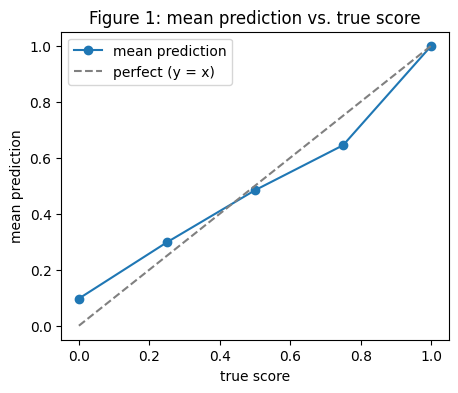

In [10]:
by_score = val.groupby("score").pred.agg(["count", "mean", "std"])
print(by_score)

plt.figure(figsize=(5, 4))
plt.plot(by_score.index, by_score["mean"], "o-", label="mean prediction")
plt.plot([0, 1], [0, 1], "--", color="gray", label="perfect (y = x)")
plt.xlabel("true score"); plt.ylabel("mean prediction")
plt.title("Figure 1: mean prediction vs. true score"); plt.legend()
plt.savefig(f"{OUT_DIR}/figure1_pred_vs_score.png", dpi=150, bbox_inches="tight")
plt.show()

### 8.3 Ten largest errors

In [11]:
val["abs_err"] = (val.pred - val.score).abs()
pd.set_option("display.max_colwidth", 60)
val.sort_values("abs_err", ascending=False).head(10)[["anchor", "target", "context", "score", "pred", "abs_err"]]

,anchor,target,context,score,pred,abs_err
5836,punch face,face punch,B05,0.00,0.939453,0.939453
3794,imaging axis,imaging of axis,G02,0.00,0.854980,0.854980
972,boom hydraulic cylinder,boom a hydraulic cylinder,E02,0.00,0.786133,0.786133
2776,end pins,wood pin,G10,0.75,-0.012161,0.762161
3790,imaging axis,image of axis,G02,0.00,0.761719,0.761719
490,average pore size,average cell size,B24,0.75,-0.003574,0.753574
1154,breech mechanism,breech loading naval gun,B29,0.75,0.038422,0.711578
6269,running tally,points balance,G08,0.75,0.075256,0.674744
7499,whose identity,customer id,G06,0.75,0.077759,0.672241
6005,return structure,return to structure,D01,0.00,0.655762,0.655762


## 9. Written answers

All numbers below come from the outputs above (validation split: `SEED = 42`, `VAL_FRACTION = 0.2`, 28,914 train rows / 7,559 val rows, 147 val anchors). Hardware: local NVIDIA RTX 3050 Laptop GPU (4 GB), fp16.

### Task 1: Fine-tuned baseline

| Model | Val Pearson | Train time |
|---|---|---|
| Starter: DeBERTa-v3-small cross-encoder, 3 epochs, lr 2e-5, batch 32 | **0.8174** | 6.9 min |

**Why hold out whole anchors?** Each anchor appears with about 50 different targets. With a random-row split, almost every validation anchor would also be in training, so the model could memorise how that anchor tends to be scored instead of learning phrase similarity. The validation score would then be too optimistic, and it would not predict the test score, because the test set uses anchors the model has never seen.

### Task 2: Baseline without fine-tuning

| Model | Fine-tuned on this data? | Val Pearson |
|---|---|---|
| Bi-encoder `sentence-transformers/all-MiniLM-L6-v2`, cosine similarity | No | **0.5814** |
| Cross-encoder DeBERTa-v3-small (Task 1) | Yes | **0.8174** |

- **Bi-encoder:** anchor and target are each turned into one vector, separately, and the prediction is the cosine of the two vectors. Neither phrase "sees" the other or the context, so word-level differences (word order, a small word like "of") are squashed into one vector before any comparison.
- **Cross-encoder:** `[CLS] anchor [SEP] target; context [SEP]` is one input, so self-attention compares every anchor token with every target token, and a regression head is trained on the raters' scores.
- **What fine-tuning added:** +0.236 Pearson (0.58 → 0.82). The pretrained bi-encoder only knows general-English similarity. Fine-tuning taught the model patent vocabulary, the use of context, and the raters' scale (for example, a hypernym is 0.5, a near synonym is 0.75). Part of the gain also comes from the cross-encoder architecture, so the two effects are not fully separated here.

### Task 3: Controlled experiments (one change at a time)

| Run | Setting changed | Val Pearson (seed 42) | Δ vs baseline | Train time | Interpretation |
|---|---|---|---|---|---|
| baseline | nothing (context = CPC section name, lr 2e-5) | 0.8174 | 0 | 6.9 min | reference |
| context=none | no context in the input | 0.8154 | −0.0020 | 11.4 min | within noise: the section name gives no measurable gain on this split |
| context=code | raw CPC code (e.g. `G02`) instead of section name | 0.8225 | +0.0051 | 7.3 min | small gain, but within seed noise (see below) |
| lr=1e-5 | learning rate 1e-5 | 0.8097 | −0.0077 | 11.8 min | under-fits in 3 epochs (higher training loss, 0.035 vs 0.030) |
| lr=5e-5 | learning rate 5e-5 | 0.8252 | +0.0078 | 7.1 min | best run; checked with a second seed below |

**Seed check** (same split, training seed changed to 7):

| Run | Seed 42 | Seed 7 | Mean | Mean Δ vs baseline |
|---|---|---|---|---|
| baseline | 0.8174 | 0.8227 | 0.8200 | 0 |
| context=code | 0.8225 | 0.8228 | 0.8226 | +0.0026 |
| lr=5e-5 | 0.8252 | 0.8244 | 0.8248 | +0.0048 |

**Conclusions (kept to what the evidence supports):**
- The baseline itself moves by **0.0053** between two seeds, so differences below ~0.005 are noise.
- **lr = 5e-5** beat both baseline seeds with both of its seeds, so it is the most likely real improvement. Even so, the mean gain (+0.005) is small and still about the size of seed noise.
- **Raw CPC code vs section name vs no context:** all three are within 0.007 of each other, and the code's +0.0026 mean gain is below noise. No context format can be called better on this evidence.
- **lr = 1e-5** is lower by 0.0077 on one seed only. It is probably under-training, but this was not rerun.
- **Training time** varied from 6 to 16 min for identical settings (baseline seed 7 took 15.8 min). The laptop GPU's speed changes with temperature and background load, so time differences here do not reflect the settings. All runs use the same model, so they have the same real cost.

### Task 4: Error analysis (best model: lr=5e-5, seed 42)

**4.1 Pearson by CPC section** (table 8.1)

| Section | Name | Val rows | Pearson |
|---|---|---|---|
| G | Physics | 1040 | **0.709** (hardest) |
| C | Chemistry; metallurgy | 1177 | 0.777 |
| A | Human necessities | 943 | 0.791 |
| D | Textiles; paper | 199 | 0.805 |
| H | Electricity | 933 | 0.809 |
| E | Fixed constructions | 373 | 0.810 |
| F | Mechanical engineering, ... | 968 | 0.852 |
| B | Performing operations; transporting | 1926 | **0.900** (easiest) |

- **G (Physics)** is the hardest. It is a very broad section (optics, measuring, computing, signalling, musical instruments), with abstract or field-specific terms ("imaging axis", "running tally", "whose identity").
- **C (Chemistry)** has chemical names and compounds that a general-domain model knows poorly.
- **B** has concrete mechanical phrases and is also the largest section in both training and validation.
- **Caveat:** validation has only 147 anchors, so each section's score depends on a handful of anchors. Small sections like D (199 rows) are especially noisy.

**4.2 Mean prediction per true score** (table 8.2, Figure 1, `figure1_pred_vs_score.png`)

| True score | Rows | Mean prediction |
|---|---|---|
| 0.00 | 1522 | 0.097 |
| 0.25 | 2465 | 0.298 |
| 0.50 | 2475 | 0.484 |
| 0.75 | 832 | 0.645 |
| 1.00 | 265 | 0.999 |

- The model **compresses towards the middle at 0 and 0.75**: score-0 pairs are pushed up (0.10), and score-0.75 pairs are pulled down (0.645).
- This matches the label imbalance. 0.25 and 0.5 make up 65% of training labels, and only 11% are 0.75 and 3% are 1.0. Under MSE loss, predicting near the common middle values is "safe".
- Score 1.0 is not compressed, because those pairs are usually near-identical strings, which are easy to spot.
- Pearson only cares about ranking, so the compression matters less than the overlap between neighbouring classes (std ≈ 0.12–0.16 inside each class).

**4.3 The 10 largest errors** (table 8.3) fall into two types:

1. **Same words, low true score (model over-predicts):**
   - "punch face" / "face punch" (true 0, pred 0.94)
   - "imaging axis" / "imaging of axis" (0 vs 0.85)
   - "imaging axis" / "image of axis" (0 vs 0.76)
   - "boom hydraulic cylinder" / "boom a hydraulic cylinder" (0 vs 0.79)
   - "return structure" / "return to structure" (0 vs 0.66)

   The cross-encoder leans on word overlap. The raters scored 0 when word order or a small word changes the meaning: a *punch face* is a part of a punch tool, a *face punch* is a hit in the face. **Several of these labels are debatable:** "boom a hydraulic cylinder" looks like a typo of the anchor, and "imaging of axis" is very close to "imaging axis", so a score of 0 seems harsh.
2. **Few shared words, high true score (model under-predicts):**
   - "running tally" / "points balance" (true 0.75, pred 0.08)
   - "whose identity" / "customer id" (0.75 vs 0.08)
   - "breech mechanism" / "breech loading naval gun" (0.75 vs 0.04)
   - "end pins" / "wood pin" (0.75 vs −0.01)
   - "average pore size" / "average cell size" (0.75 vs 0.00)

   These need **domain or field-specific knowledge**. In foams, "pore" and "cell" mean the same thing. In G10 (musical instruments), an end pin is often a wood pin. "Id" is an abbreviation of "identity". The small model does not know these links. "end pins" / "wood pin" = 0.75 is also debatable.

### Task 5: Late submission and leaderboard scores

- **Final model:** `lr=5e-5`, chosen by **validation** score only (best single-seed 0.8252 and best two-seed mean 0.8248). It was chosen before any leaderboard score was seen.
- **Submission notebook:** Kaggle notebook `anshupadhyay14/lab1-patent-matching`, **Version 2**. It is this notebook with `SUBMIT_MODE = True`, `FINAL = "lr=5e-5"`, GPU on and Internet off. It trains only the final model (3.4 min on a Kaggle GPU) and writes `/kaggle/working/submission.csv`.
- Version 1 of the Kaggle notebook crashed before writing a submission: `warmup_ratio` was removed from `TrainingArguments` in transformers 5, which Kaggle uses. It was replaced by the equivalent `warmup_steps` (10% of the training steps). Version 1 produced no score, so it is not a submission.

**All submissions made** (only one):

| # | Notebook version | Model | Val Pearson (Kaggle re-run) | Public score | Private score |
|---|---|---|---|---|---|
| 1 | Version 2 | DeBERTa-v3-small, lr=5e-5 | 0.8254 | **0.7966** | **0.8204** |

**Comparison:**
- **Validation 0.825 vs private 0.820:** very close (−0.005). The anchor-grouped split was a good estimate of performance on unseen anchors.
- **Public 0.797:** about 0.02–0.03 lower than both validation and private.

**Why the scores can differ:**
- **Test-set size:** the public part of the test set is a small fraction of the hidden test pairs, so its score is noisier. The private part is larger, so it is closer to the validation score.
- **Different anchors and section mix:** the test set uses anchors that were never in training. Section-level Pearson in Task 4 ranges from 0.71 (G) to 0.90 (B), so if the public part happens to contain more hard anchors or more G/C rows, its score is lower.
- **Selection bias:** `lr=5e-5` was chosen because it had the best validation score, so its validation number is slightly optimistic. The leaderboard was not used for any choice.
- **Small differences between runs:** the Kaggle re-run gave 0.8254 vs 0.8252 locally (GPU non-determinism), which is much smaller than the public/private gap.

### References
- Kaggle. *U.S. Patent Phrase to Phrase Matching* competition (Overview, Data, Rules). https://www.kaggle.com/competitions/us-patent-phrase-to-phrase-matching
- Aslanyan, G., & Wetherbee, I. (2022). *Patents Phrase to Phrase Semantic Matching Dataset.* arXiv:2208.01171.
- He, P., Gao, J., & Chen, W. (2021). *DeBERTaV3.* arXiv:2111.09543. Checkpoint `microsoft/deberta-v3-small` (MIT license).
- Reimers, N., & Gurevych, I. (2019). *Sentence-BERT.* EMNLP 2019, arXiv:1908.10084. Checkpoint `sentence-transformers/all-MiniLM-L6-v2` (Apache 2.0).
- Hugging Face `transformers` Trainer and `sentence-transformers` documentation.
- Course starter notebook: the pipeline structure, CPC section names and the tokenizer `TemplateProcessing` fix are adapted from it.